<a href="https://colab.research.google.com/github/tahta-id/Project-Google-Colab/blob/main/breast_ultrasound_images_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install kagglehub opencv-python numpy pandas tensorflow scikit-learn seaborn matplotlib

--- Mengunduh Dataset Breast Ultrasound via kagglehub ---


100%|██████████| 195M/195M [00:01<00:00, 159MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/sabahesaraki/breast-ultrasound-images-dataset/versions/1
Total gambar valid (tanpa file mask): 780
Daftar Kelas USG Payudara: ['malignant', 'normal', 'benign']
Sampel citra USG Payudara untuk Modul 1-3: /root/.cache/kagglehub/datasets/sabahesaraki/breast-ultrasound-images-dataset/versions/1/Dataset_BUSI_with_GT/malignant/malignant (124).png



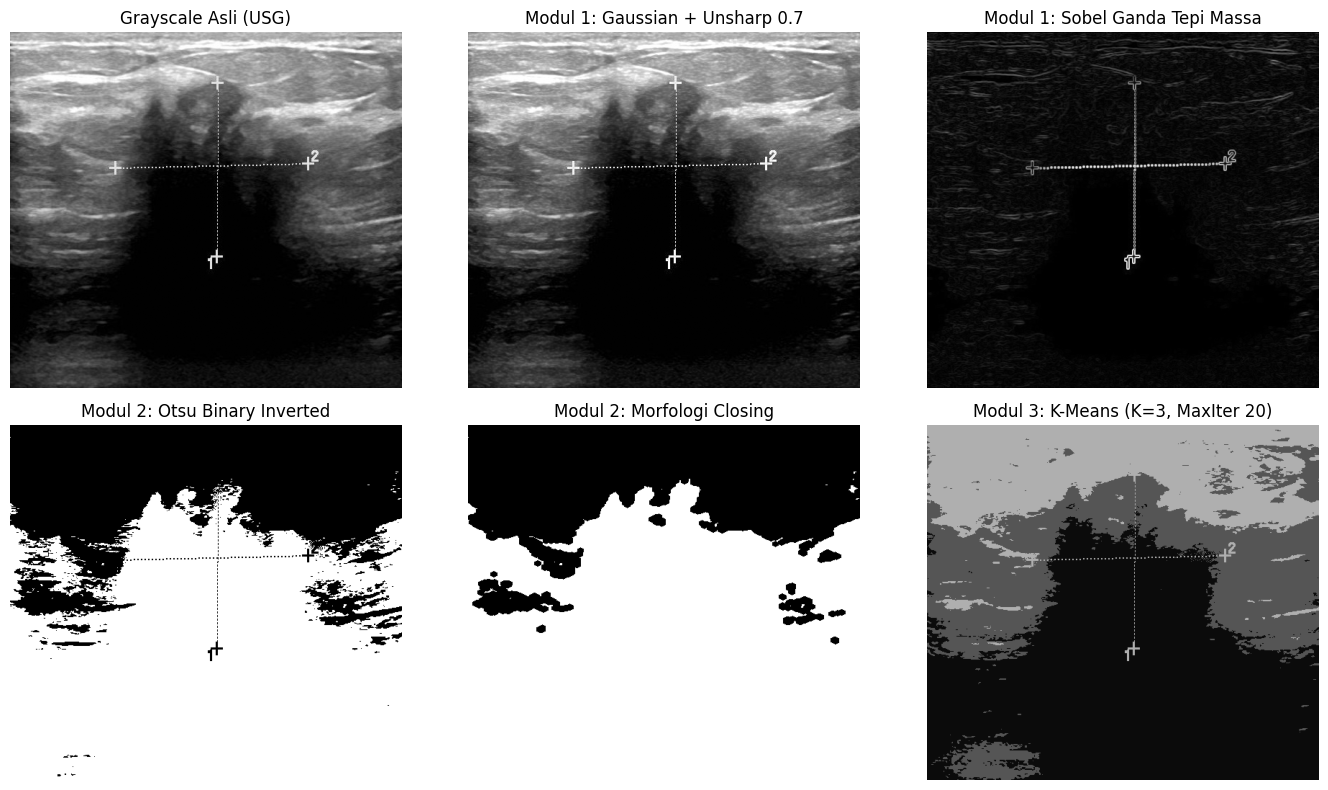


--- Modul 4: Membagi Dataset & Menyiapkan Data Generator ---
Found 624 validated image filenames belonging to 3 classes.
Found 156 validated image filenames belonging to 3 classes.
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

--- Melatih Model EfficientNetB0 (Fine-Tuning 20 Layer) ---
Epoch 1/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 56s 2s/step - accuracy: 0.2981 - loss: 1.1363 - val_accuracy: 0.2692 - val_loss: 1.1933
Epoch 2/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 43s 2s/step - accuracy: 0.4920 - loss: 1.0630 - val_accuracy: 0.2692 - val_loss: 1.1739
Epoch 3/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 46s 2s/step - accuracy: 0.5353 - loss: 1.0274 - val_accuracy: 0.2692 - val_loss: 1.1516
Epoch 4/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 44s 2s/step - accuracy: 0.5401 - loss: 1.0099 - val_accuracy: 0.2692 - val_loss: 1.1307
Epoch 5/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 46s 2s/step - accuracy: 0.5561 - loss: 0.9878 - val_accuracy: 0.2692 - val_loss: 1.1141
5/5 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step

================ CLASSIFICATION REPORT ====

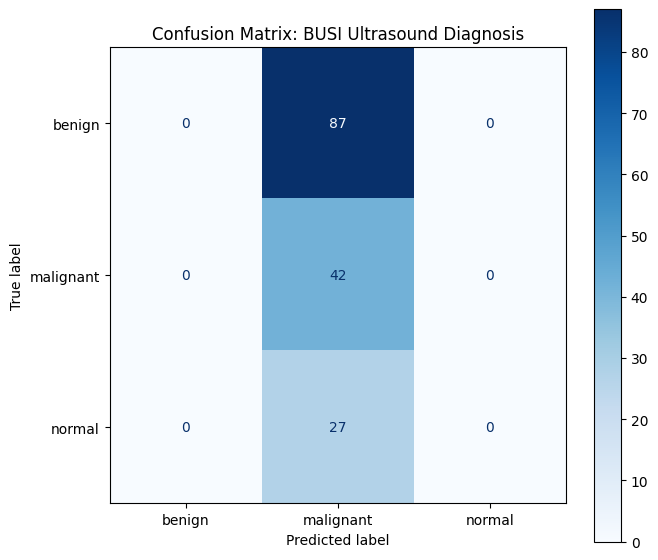

In [2]:
import os
import glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import kagglehub

# =====================================================================
# 0. UNDUH DATASET MENGGUNAKAN KAGGLEHUB & PENGOLAHAN PATH DATASET
# =====================================================================
print("--- Mengunduh Dataset Breast Ultrasound via kagglehub ---")
path = kagglehub.dataset_download("sabahesaraki/breast-ultrasound-images-dataset")
print("Path to dataset files:", path)

# 1. Cari semua file gambar (.png/.jpg) di seluruh subfolder dataset
all_images = glob.glob(os.path.join(path, "**", "*.png"), recursive=True) + \
             glob.glob(os.path.join(path, "**", "*.jpg"), recursive=True)

if not all_images:
    raise FileNotFoundError("Tidak ditemukan file gambar di dalam dataset Breast Ultrasound!")

# 2. Filter gambar utama (abaikan gambar mask biner bawaan dataset yang berakhiran '_mask')
main_images = [f for f in all_images if "_mask" not in os.path.basename(f).lower()]

# 3. Susun DataFrame berdasarkan kelas folder: benign, malignant, normal
data = []
for img_path in main_images:
    parent_dir = os.path.basename(os.path.dirname(img_path))
    data.append({'file_path': img_path, 'class_str': parent_dir})

df = pd.DataFrame(data)

# Pastikan label sesuai dengan 3 kelas utama: benign, malignant, normal
valid_classes = ['benign', 'malignant', 'normal']
df = df[df['class_str'].str.lower().isin(valid_classes)].reset_index(drop=True)

print(f"Total gambar valid (tanpa file mask): {len(df)}")
print(f"Daftar Kelas USG Payudara: {df['class_str'].unique().tolist()}")

# Ambil 1 sampel gambar USG untuk demonstrasi Modul 1-3
sample_img_path = df['file_path'].iloc[0]
print(f"Sampel citra USG Payudara untuk Modul 1-3: {sample_img_path}\n")


# =====================================================================
# MODUL 1: Gaussian Blur (Speckle Noise), Unsharp 0.7 & Sobel Ganda
# =====================================================================
def modul_1_processing(image_path):
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        raise ValueError(f"Gagal memuat citra: {image_path}")

    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    # 1. Reduksi speckle noise ultrasonik dengan Gaussian blur spasial (kernel 5x5, sigmaX=1.5)
    blurred = cv2.GaussianBlur(gray, (5, 5), 1.5)

    # 2. Penajaman kontur ekogenik benjolan massa dengan penambahan bobot alpha 0.7
    # Sharpened = Gray + 0.7 * (Gray - Blurred)
    high_freq_detail = cv2.subtract(gray, blurred)
    sharpened = cv2.addWeighted(gray, 1.0, high_freq_detail, 0.7, 0)

    # 3. Hitung tepi anomali massa bergerigi kasar menggunakan matriks Sobel ganda (gx dan gy)
    sobel_x = cv2.Sobel(sharpened, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(sharpened, cv2.CV_64F, 0, 1, ksize=3)

    sobel_mag = cv2.magnitude(sobel_x, sobel_y)
    sobel_uint8 = cv2.normalize(sobel_mag, None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)

    return gray, sharpened, sobel_uint8


# =====================================================================
# MODUL 2: Binerisasi Otsu Hypoechoic & Closing Morfologi
# =====================================================================
def modul_2_processing(sharpened_img):
    # 1. Binerisasi otomatis Otsu Inverted (massa hypoechoic gelap diisolasi menjadi area putih)
    _, otsu_thresh = cv2.threshold(sharpened_img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    # 2. Operasi morfologi closing untuk mengisi rongga bercak gema palsu di dalam tumor
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    clean_mask = cv2.morphologyEx(otsu_thresh, cv2.MORPH_CLOSE, kernel, iterations=2)

    return otsu_thresh, clean_mask


# =====================================================================
# MODUL 3: Klasterisasi K-Means 3 Pantulan Utama (Max Iterasi 20)
# =====================================================================
def modul_3_processing(image_path):
    img_bgr = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # 1. Rombak matriks penampang warna organ (H, W, 3) menjadi (-1, 3) float32
    pixel_values = img_rgb.reshape((-1, 3))
    pixel_values = np.float32(pixel_values)

    # 2. K-Means (K=3) dengan kriteria terminasi maksimum 20 iterasi:
    # Memblokir warna menjadi: cairan/kista anechoic hitam, fibroglandular abu-abu, & lemak subkutan terang
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 0.2)
    k = 3

    _, labels, centers = cv2.kmeans(pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

    centers = np.uint8(centers)
    segmented_data = centers[labels.flatten()]
    segmented_image = segmented_data.reshape(img_rgb.shape)

    return segmented_image


# =====================================================================
# MODUL 4: Fine-Tuning EfficientNetB0 (20 Layer Unfreeze, LR 1e-5, Adam)
# =====================================================================
def modul_4_train_and_eval(df, img_size=(224, 224), batch_size=32, epochs=5):
    print("\n--- Modul 4: Membagi Dataset & Menyiapkan Data Generator ---")

    # Pembagian Stratified Split (80% Train, 20% Val)
    train_df, val_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['class_str'])

    datagen = ImageDataGenerator(rescale=1./255)

    train_gen = datagen.flow_from_dataframe(
        dataframe=train_df,
        x_col='file_path',
        y_col='class_str',
        target_size=img_size,
        batch_size=batch_size,
        class_mode='categorical',
        shuffle=True
    )

    val_gen = datagen.flow_from_dataframe(
        dataframe=val_df,
        x_col='file_path',
        y_col='class_str',
        target_size=img_size,
        batch_size=batch_size,
        class_mode='categorical',
        shuffle=False
    )

    num_classes = len(train_df['class_str'].unique())

    # 1. Konstruksi Model EfficientNetB0 Pre-trained
    base_model = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(img_size[0], img_size[1], 3))
    base_model.trainable = True

    # Bekukan seluruh layer KECUALI 20 lapisan terdalam (fine-tuning phase)
    for layer in base_model.layers[:-20]:
        layer.trainable = False

    inputs = layers.Input(shape=(img_size[0], img_size[1], 3))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = models.Model(inputs, outputs)

    # 2. Kompilasi dengan optimizer Adam dan Learning Rate 1e-5
    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-5),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    print("\n--- Melatih Model EfficientNetB0 (Fine-Tuning 20 Layer) ---")
    model.fit(train_gen, validation_data=val_gen, epochs=epochs)

    # 3. Evaluasi Prediksi pada Data Validasi
    val_gen.reset()
    y_pred_probs = model.predict(val_gen)
    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = val_gen.classes

    labels_map = {v: k for k, v in val_gen.class_indices.items()}
    class_names = [labels_map[i] for i in range(num_classes)]

    print("\n================ CLASSIFICATION REPORT ================")
    print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

    # Visualisasi Matriks Evaluasi dengan ConfusionMatrixDisplay
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

    fig, ax = plt.subplots(figsize=(7, 6))
    disp.plot(cmap='Blues', ax=ax)
    plt.title('Confusion Matrix: BUSI Ultrasound Diagnosis')
    plt.tight_layout()
    plt.show()


# =====================================================================
# EKSEKUSI PIPELINE
# =====================================================================
if __name__ == "__main__":
    # Jalankan Modul 1
    gray_img, sharpened_img, sobel_uint8 = modul_1_processing(sample_img_path)

    # Jalankan Modul 2
    otsu_thresh, clean_mask = modul_2_processing(sharpened_img)

    # Jalankan Modul 3
    kmeans_segmented = modul_3_processing(sample_img_path)

    # Visualisasi Hasil Modul 1 - 3
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    axes[0, 0].imshow(gray_img, cmap='gray')
    axes[0, 0].set_title('Grayscale Asli (USG)')

    axes[0, 1].imshow(sharpened_img, cmap='gray')
    axes[0, 1].set_title('Modul 1: Gaussian + Unsharp 0.7')

    axes[0, 2].imshow(sobel_uint8, cmap='gray')
    axes[0, 2].set_title('Modul 1: Sobel Ganda Tepi Massa')

    axes[1, 0].imshow(otsu_thresh, cmap='gray')
    axes[1, 0].set_title('Modul 2: Otsu Binary Inverted')

    axes[1, 1].imshow(clean_mask, cmap='gray')
    axes[1, 1].set_title('Modul 2: Morfologi Closing')

    axes[1, 2].imshow(kmeans_segmented)
    axes[1, 2].set_title('Modul 3: K-Means (K=3, MaxIter 20)')

    for ax in axes.ravel():
        ax.axis('off')
    plt.tight_layout()
    plt.show()

    # Jalankan Modul 4 (Fine-tuning EfficientNetB0)
    modul_4_train_and_eval(df, epochs=5)